In [77]:
import pandas as pd
import numpy as np
import anndata as ad
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------
# Load 
# ------------------------------------------------------------------------
meta = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges34_genes_input.RUNFILE.csv")
scores = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges__breast.csv")

# ------------------------------------------------------------------------
# Clean metadata
# ------------------------------------------------------------------------
meta = meta.drop_duplicates()

snp_gene_map = meta.copy()
meta_resolved = meta.sort_values(['SNP', 'dist']).drop_duplicates('SNP', keep='first')

scores = scores.set_index('SNP')
meta_resolved = meta_resolved.set_index('SNP')

assert set(scores.index) == set(meta_resolved.index)

scores = scores.drop(columns='macro_mean')

var = pd.DataFrame(index=scores.columns)
var['cell_type'] = var.index

# ------------------------------------------------------------------------
# Generate anndata object
# ------------------------------------------------------------------------
adata = ad.AnnData(
    X=scores.values.astype(np.float32),
    obs=meta_resolved,
    var=var
)

# stash the full (unresolved) SNP-gene mapping for the one/few multi-gene SNPs
adata.uns['snp_gene_map_full'] = snp_gene_map.reset_index(drop=True)
adata

AnnData object with n_obs × n_vars = 10066 × 58
    obs: 'chrom', 'snp_chromStart', 'snp_chromEnd', 'ref', 'alt', 'chrom_gene', 'tss', 'tss_chromEnd', 'strand', 'gene_name', 'gene_id', 'cage_used', 'dist'
    var: 'cell_type'
    uns: 'snp_gene_map_full'
    layers: None (.X)

In [78]:
adata.obs

,chrom,snp_chromStart,snp_chromEnd,ref,alt,chrom_gene,tss,tss_chromEnd,strand,gene_name,gene_id,cage_used,dist
SNP,,,,,,,,,,,,,
10_89624151_C_T,10,89624151,89624152,C,T,10,89623389,89623390,+,PTEN,ENSG00000171862,True,762
10_89624161_A_C,10,89624161,89624162,A,C,10,89623389,89623390,+,PTEN,ENSG00000171862,True,772
10_89624199_C_T,10,89624199,89624200,C,T,10,89623389,89623390,+,PTEN,ENSG00000171862,True,810
10_89624200_T_C,10,89624200,89624201,T,C,10,89623389,89623390,+,PTEN,ENSG00000171862,True,811
10_89624213_A_C,10,89624213,89624214,A,C,10,89623389,89623390,+,PTEN,ENSG00000171862,True,824
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8_90996799_T_A,8,90996799,90996800,T,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,72
8_90996805_G_A,8,90996805,90996806,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,66
8_90996810_G_A,8,90996810,90996811,G,A,8,90996871,90996872,-,NBN,ENSG00000104320,True,61


/storage/scratch/tmp/ipykernel_4052844/4175353072.py:5: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata)


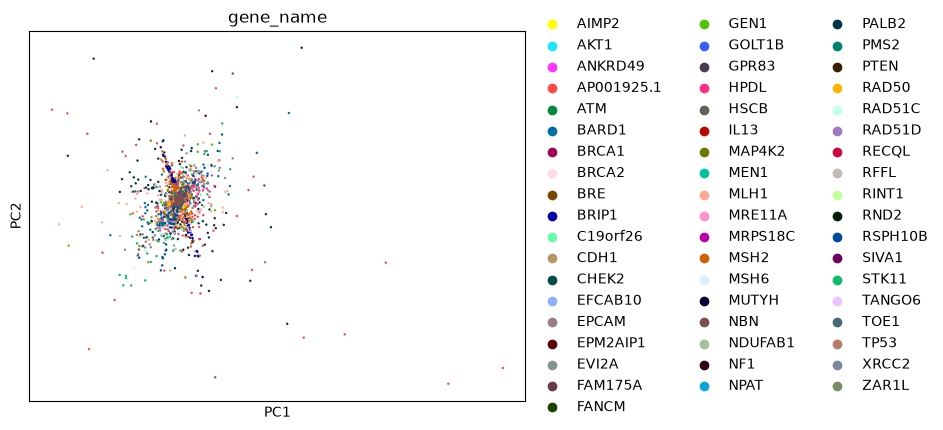

In [79]:
import scanpy as sc

sc.pp.pca(adata, n_comps=20)
sc.pp.neighbors(adata)
sc.tl.leiden(adata)
sc.pl.pca(adata, color='gene_name')

In [80]:

adata_ct = adata.T

X = adata_ct.X

cell_types = adata_ct.obs_names.to_numpy()
snp_ids = adata_ct.var_names.to_numpy()

gene_names = adata_ct.var['gene_name'].to_numpy()


pca = PCA(n_components=2)
scores = pca.fit_transform(X - X.mean(axis=0))
loadings = pca.components_.T

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Scores shape:", scores.shape, "Loadings shape:", loadings.shape)




Explained variance ratio: [0.4441472  0.20804267]
Scores shape: (58, 2) Loadings shape: (10066, 2)


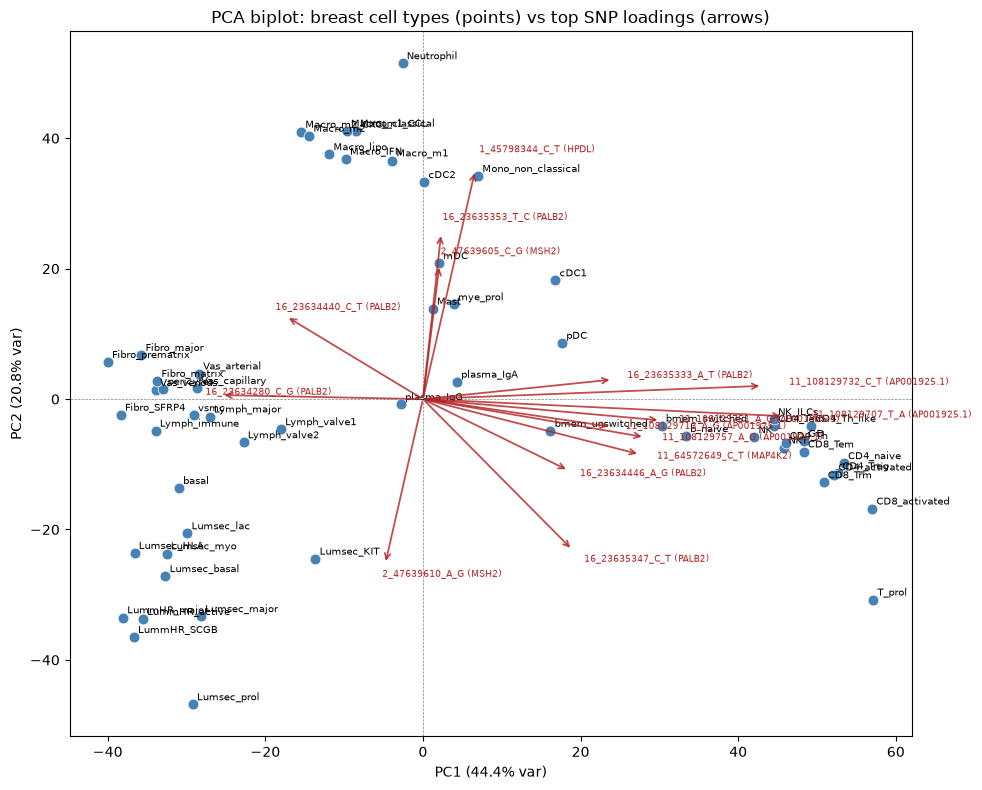

In [81]:
loading_mag = np.linalg.norm(loadings, axis=1)
top_n = 15
top_idx = np.argsort(loading_mag)[-top_n:]

# Scale factor so arrows are visible relative to the score spread
scale = (np.abs(scores).max() / np.abs(loadings[top_idx]).max()) * 0.8


fig, ax = plt.subplots(figsize=(10, 8))

# Cell type points
ax.scatter(scores[:, 0], scores[:, 1], c='steelblue', s=60, zorder=3, edgecolor='white', linewidth=0.5)
for i, ct in enumerate(cell_types):
    ax.annotate(ct, (scores[i, 0], scores[i, 1]), fontsize=7, xytext=(3, 3),
                textcoords='offset points', zorder=4)

# SNP arrows
for i in top_idx:
    x, y = loadings[i, 0] * scale, loadings[i, 1] * scale
    ax.annotate('', xy=(x, y), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='firebrick', lw=1.3, alpha=0.8),
                zorder=5)
    label = f"{snp_ids[i]} ({gene_names[i]})"
    ax.text(x * 1.08, y * 1.08, label, fontsize=6.5, color='firebrick', zorder=6)
 
ax.axhline(0, color='grey', lw=0.5, linestyle='--')
ax.axvline(0, color='grey', lw=0.5, linestyle='--')
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
ax.set_title("PCA biplot: breast cell types (points) vs top SNP loadings (arrows)")
plt.tight_layout()


In [1]:
import pandas as pd
import seaborn as sns

In [2]:
#TODO

# Annotate the SNP, or add another column, with which gene it belongs to
# Its in the Seqweaver_bridges34_genes_input.RUNFILE.csv

In [3]:
df = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/Seqweaver_bridges__breast.csv", index_col='SNP').drop("macro_mean", axis=1)
df

,Lumsec_major,CD4_naive,Vas_arterial,T_prol,Lymph_valve2,Vas_venous,pericytes,Lumsec_myo,CD8_Tem,b_naive,...,Macro_m1_CCL,plasma_IgA,Fibro_SFRP4,Lumsec_HLA,Mono_non_classical,LummHR_active,Macro_IFN,CD4_activated,Fibro_major,pDC
SNP,,,,,,,,,,,,,,,,,,,,,
1_45794979_C_G,-0.098642,-0.037530,-0.120704,-0.046177,-0.168627,-0.097775,-0.152277,-0.121232,-0.044770,-0.035904,...,-0.058157,-0.086031,-0.202274,-0.101641,-0.034030,-0.114761,-0.046459,-0.035442,-0.163672,-0.082305
1_45794983_G_A,-0.194202,0.000243,0.060638,-0.025970,0.062815,0.007582,0.126519,-0.184144,-0.017531,0.003549,...,0.069310,-0.019523,0.158286,-0.343143,0.071504,-0.189323,0.095811,-0.039422,0.146556,0.040003
1_45794993_G_A,-0.246038,-0.215814,-0.280539,-0.263582,-0.366701,-0.284952,-0.361204,-0.264380,-0.211859,-0.171079,...,-0.162856,-0.321782,-0.525595,-0.224855,-0.117842,-0.203701,-0.158149,-0.265682,-0.417115,-0.308078
1_45794998_G_C,0.085459,0.030993,0.058055,0.033443,0.065792,0.050949,0.027174,0.084003,0.030082,0.019765,...,0.009364,0.034013,0.037675,0.088051,0.004546,0.093291,0.009438,0.037924,0.036089,0.015332
1_45795002_G_A,0.156451,0.007813,0.120878,0.005290,0.188081,0.116439,0.121432,0.160059,0.020633,0.029458,...,0.066755,0.052820,0.095924,0.184090,0.052263,0.155310,0.050283,-0.003054,0.116481,0.039094
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8_90996799_T_A,0.284476,0.224080,-0.263773,0.068867,-0.479779,-0.189315,-0.574833,-0.041605,0.092080,0.347767,...,-0.481346,0.174968,-0.753059,0.088084,-0.440934,0.022356,-0.395922,0.338504,-0.713791,-0.032397
8_90996805_G_A,-0.076384,0.051730,-0.481214,-0.082722,-0.312230,-0.388185,-0.277128,-0.145873,-0.008884,-0.358352,...,-0.445344,-0.257611,-0.200781,-0.274405,-0.373441,-0.157192,-0.629108,0.134022,-0.226881,-0.418884
8_90996810_G_A,0.848272,0.764258,0.287601,0.643362,0.251251,0.362762,0.128682,0.629247,0.512433,0.763829,...,-0.188455,0.278797,0.250662,0.539204,-0.102425,0.595538,-0.173763,0.941237,0.069983,0.282454


In [4]:
df_filtered = df[(df.abs() > 5).any(axis=1)]
df_filtered

,Lumsec_major,CD4_naive,Vas_arterial,T_prol,Lymph_valve2,Vas_venous,pericytes,Lumsec_myo,CD8_Tem,b_naive,...,Macro_m1_CCL,plasma_IgA,Fibro_SFRP4,Lumsec_HLA,Mono_non_classical,LummHR_active,Macro_IFN,CD4_activated,Fibro_major,pDC
SNP,,,,,,,,,,,,,,,,,,,,,
1_45800062_C_T,-4.046251,0.832841,2.717962,2.096525,3.282668,3.347677,-0.871141,-3.384650,0.243556,0.878050,...,3.365031,-0.503543,-1.527568,-2.855636,3.792672,-1.770642,3.405108,1.141663,-0.936324,3.025449
1_45800154_C_G,-2.937479,5.686300,1.466255,7.628654,2.204314,1.524374,-1.507601,-3.053122,4.277064,2.576430,...,1.845323,0.755468,-2.874401,-2.723168,3.338236,-2.855069,2.116407,6.130876,-1.735344,3.221803
1_45800178_G_A,-0.258585,-0.231883,3.903241,0.093547,3.451556,4.159781,1.005605,0.190586,-0.182963,0.765990,...,3.694377,0.514420,0.030965,1.363988,3.655623,0.029311,3.779967,-0.402673,0.528756,2.723759
1_45805566_G_C,-3.841604,-1.576696,-1.976987,-3.040386,-1.743357,-3.003495,-1.542506,-2.976409,-1.887441,-1.771234,...,-1.984390,-2.141738,-1.242069,-3.278260,-2.155736,-3.067648,-2.159203,-1.574598,-1.386133,-2.032047
1_45805624_G_A,7.555773,3.560311,4.349861,2.954771,5.517923,5.569538,3.998787,6.866773,3.138270,3.960304,...,3.028439,4.708424,5.381764,8.015066,3.160007,6.411478,3.309010,3.640033,4.227689,4.313324
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7_6048664_G_C,-3.854455,-2.248674,-2.619266,-4.864861,-2.968393,-2.781076,-2.587568,-3.334082,-3.007444,-2.551990,...,-2.245535,-3.004622,-2.230204,-3.266782,-2.156479,-4.711429,-2.395373,-2.210790,-2.411218,-1.889903
7_6048669_G_A,-5.237798,-3.035845,-3.717007,-6.573653,-4.228094,-3.894938,-3.885539,-4.512817,-3.694866,-3.592379,...,-2.886019,-4.150117,-3.319888,-4.825149,-2.859024,-5.641647,-3.128224,-2.949529,-3.516625,-2.504679
7_105172775_G_A,-2.406260,-3.986986,-2.735592,-5.427804,-2.776761,-2.751608,-2.254498,-2.460981,-4.126721,-4.023081,...,-2.596220,-3.026631,-2.314967,-2.105788,-3.095764,-2.762963,-2.768378,-4.911872,-2.138836,-3.990853


<Axes: ylabel='Count'>

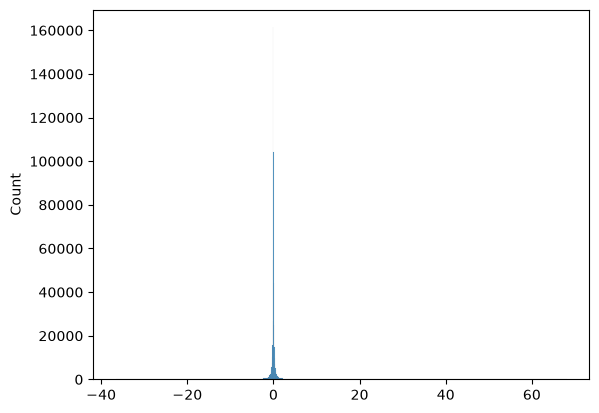

In [5]:
all_values = df.stack()

sns.histplot(
    data=all_values
)

<Axes: ylabel='Count'>

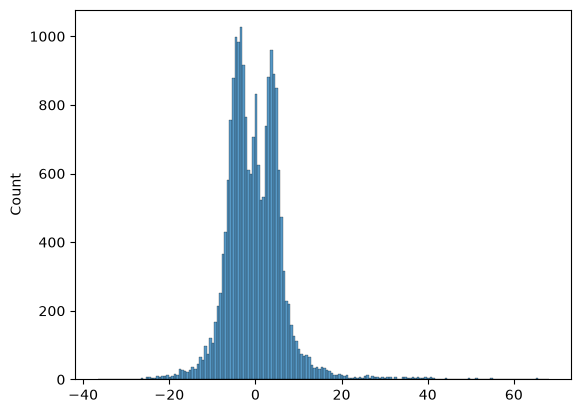

In [6]:
all_values = df_filtered.stack()

sns.histplot(
    data=all_values
)

/storage/mathelierarea/processed/eirikhoy/action_var/.venv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/storage/mathelierarea/processed/eirikhoy/action_var/.venv/lib/python3.12/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


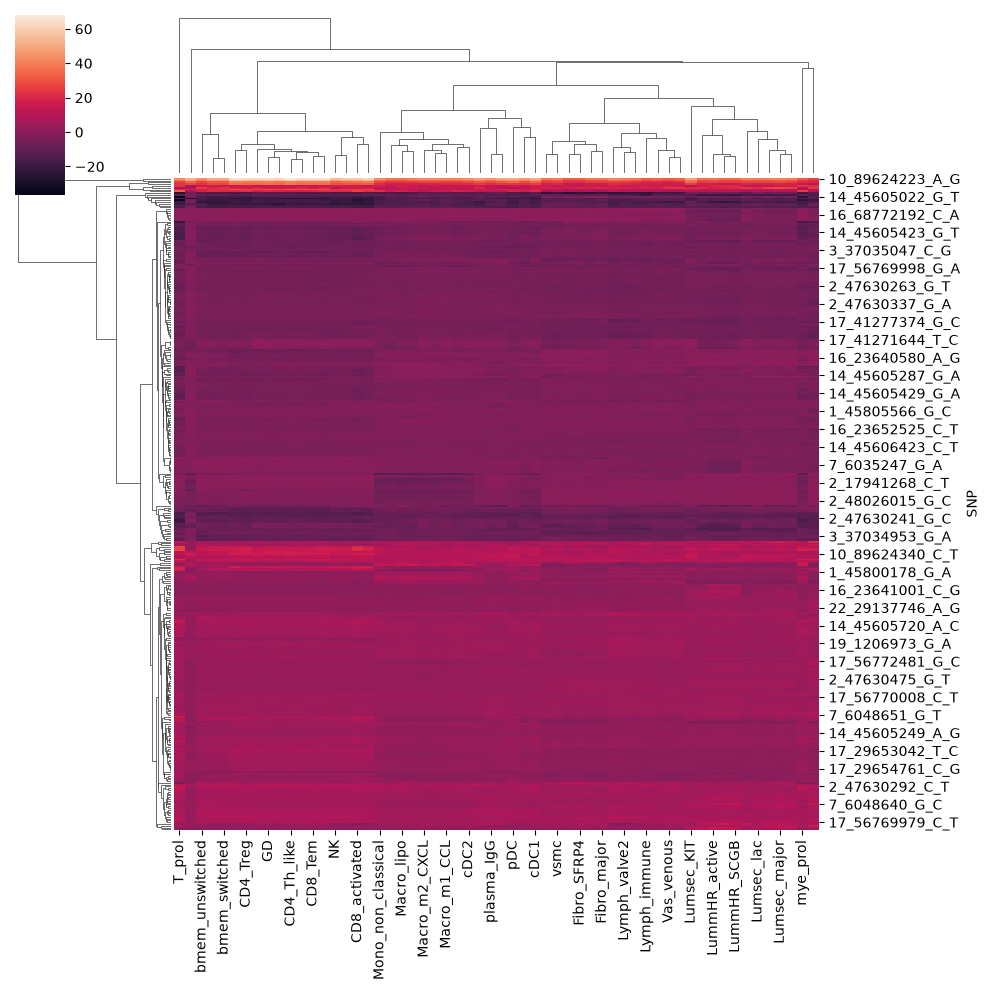

In [7]:
sns.clustermap(df_filtered)

<Axes: ylabel='Count'>

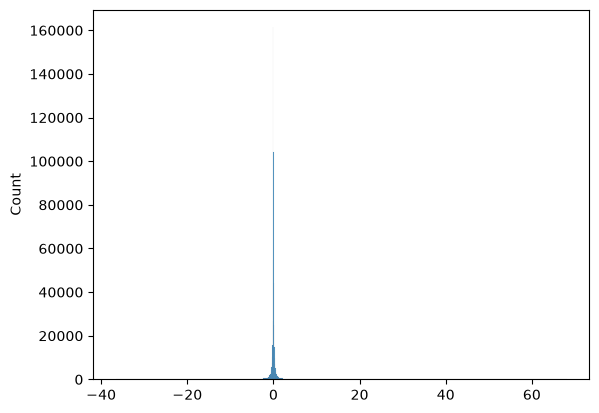

In [43]:
X = df.copy()

sns.histplot(X.stack())

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd


#X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components = 10, svd_solver='auto')
X_pca = pca.fit_transform(X)

# variance explained
pca.explained_variance_ratio_


array([0.89986954, 0.04055677, 0.02008231, 0.01265957, 0.00914017,
       0.0036797 , 0.0025924 , 0.00196823, 0.00159256, 0.00145217])

---

PCA using ISLRp lab method
---


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.datasets import get_rdataset
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import \
    (KMeans, 
     AgglomerativeClustering)
from scipy.cluster.hierarchy import \
    (dendrogram,
     cut_tree)

scaler = StandardScaler(with_std=True,
                        with_mean=True)
df_scaled = scaler.fit_transform(df)
pca = PCA()
pca.fit(df_scaled)
scores = pca.transform(df_scaled)
scores

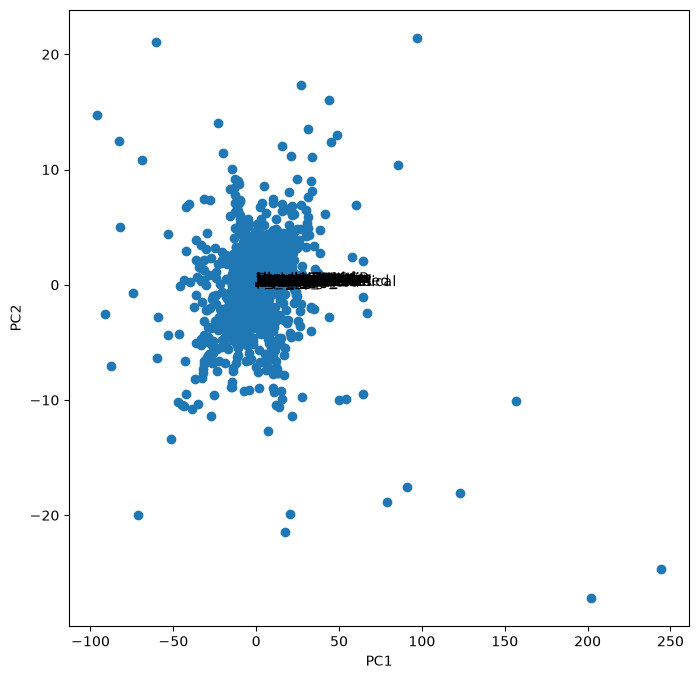

In [21]:
i, j = 0, 1
fig, ax = plt.subplots(1, 1, figsize=(8,8))
ax.scatter(scores[:, 0], scores[:, 1])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pca.components_.shape[1]):
    ax.arrow(0, 0, pca.components_[i,k], pca.components_[j,k])
    ax.text(pca.components_[i,k],
            pca.components_[j, k],
            df.columns[k])

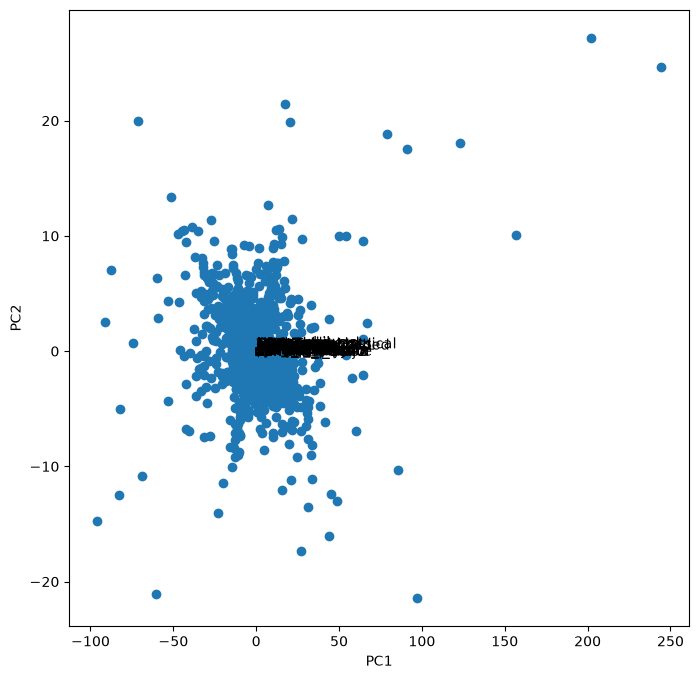

In [22]:
scale_arrow = s_ = 2
scores[:, 1] *= -1
pca.components_[1] *= -1
fig, ax = plt.subplots(1, 1, figsize=(8,8))
ax.scatter(scores[:, 0], scores[:, 1])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pca.components_.shape[1]):
    ax.arrow(0, 0, s_*pca.components_[i, k], s_*pca.components_[j,k])
    ax.text(s_*pca.components_[i,k],
            s_*pca.components_[j,k],
            df.columns[k])

In [26]:
df_T = df.T
df_T

SNP,1_45794979_C_G,1_45794983_G_A,1_45794993_G_A,1_45794998_G_C,1_45795002_G_A,1_45795006_G_A,1_45795007_C_T,1_45795010_C_T,1_45795011_A_G,1_45795013_T_C,...,8_90996779_A_C,8_90996788_A_G,8_90996791_G_A,8_90996791_G_T,8_90996794_C_T,8_90996799_T_A,8_90996805_G_A,8_90996810_G_A,8_90996815_C_T,8_90996827_G_C
Lumsec_major,-0.098642,-0.194202,-0.246038,0.085459,0.156451,0.399092,0.208638,-0.156619,-0.142100,-0.221734,...,1.085997,0.459476,-0.643215,-2.789815,-1.117645,0.284476,-0.076384,0.848272,1.762567,-1.530450
CD4_naive,-0.037530,0.000243,-0.215814,0.030993,0.007813,0.212656,-0.027812,-0.219238,-0.075324,-0.080234,...,0.352890,-0.135805,-0.507266,-2.061146,-0.356475,0.224080,0.051730,0.764258,0.889694,-1.123052
Vas_arterial,-0.120704,0.060638,-0.280539,0.058055,0.120878,0.336997,0.072693,-0.239815,-0.188873,-0.189830,...,0.695945,-0.132026,-0.675130,-2.062694,-0.870792,-0.263773,-0.481214,0.287601,1.282415,-0.758527
T_prol,-0.046177,-0.025970,-0.263582,0.033443,0.005290,0.263381,-0.036592,-0.281834,-0.097217,-0.087863,...,0.537355,-0.072996,-0.597021,-2.531419,-0.688105,0.068867,-0.082722,0.643362,0.817321,-1.271223
Lymph_valve2,-0.168627,0.062815,-0.366701,0.065792,0.188081,0.434461,0.073516,-0.324874,-0.299276,-0.268918,...,0.922453,0.167614,-0.766279,-2.281712,-1.065464,-0.479779,-0.312230,0.251251,0.927034,-0.787272
Vas_venous,-0.097775,0.007582,-0.284952,0.050949,0.116439,0.356132,0.066109,-0.254213,-0.174623,-0.174977,...,0.760837,0.120445,-0.705341,-2.129710,-0.882685,-0.189315,-0.388185,0.362762,1.635840,-1.070555
pericytes,-0.152277,0.126519,-0.361204,0.027174,0.121432,0.423105,0.076832,-0.328527,-0.165769,-0.227193,...,0.923145,0.045427,-0.571420,-1.774601,-0.818931,-0.574833,-0.277128,0.128682,0.865518,-0.391166
Lumsec_myo,-0.121232,-0.184144,-0.264380,0.084003,0.160059,0.412619,0.263781,-0.133188,-0.155985,-0.239479,...,1.134665,0.357395,-0.528544,-2.435000,-1.096452,-0.041605,-0.145873,0.629247,1.636323,-1.308810
CD8_Tem,-0.044770,-0.017531,-0.211859,0.030082,0.020633,0.211852,-0.010174,-0.207812,-0.074709,-0.082072,...,0.383693,-0.165510,-0.483006,-1.933230,-0.328014,0.092080,-0.008884,0.512433,0.792097,-0.879414
b_naive,-0.035904,0.003549,-0.171079,0.019765,0.029458,0.193228,0.001407,-0.170344,-0.051239,-0.047647,...,0.468378,-0.391514,-0.886670,-3.338156,-0.679593,0.347767,-0.358352,0.763829,1.210527,-1.396000


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.datasets import get_rdataset
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import \
    (KMeans, 
     AgglomerativeClustering)
from scipy.cluster.hierarchy import \
    (dendrogram,
     cut_tree)





scaler = StandardScaler(with_std=True,
                        with_mean=True)
df_scaled = scaler.fit_transform(df_T)
pca = PCA()
pca.fit(df_scaled)
scores = pca.transform(df_scaled)
scores

array([[-5.42579379e+01,  6.26757289e+01, -2.06512129e+01, ...,
        -7.30188557e-01,  1.26096998e-01,  5.06913016e-14],
       [ 6.82024067e+01,  1.91348206e+01,  3.25139593e+01, ...,
         1.07087639e+00, -2.01908033e-01,  9.91664144e-14],
       [-6.61023824e+01, -3.92064318e+01,  2.24739824e+01, ...,
         7.94671237e-02, -2.62788514e-01, -2.97044579e-14],
       ...,
       [ 5.91590082e+01,  1.21229247e+01,  6.36100634e+01, ...,
         2.51029540e-01, -4.80069484e-03,  1.73704013e-13],
       [-3.73655157e+01, -1.38467088e+01, -2.99686672e+01, ...,
         2.78430089e-01,  6.00158072e-02, -2.17785063e-14],
       [ 3.11863035e+01, -7.78617888e+00,  1.79549503e+01, ...,
        -8.29267723e-02,  7.48822878e-03, -2.04184831e-14]],
      shape=(58, 58))

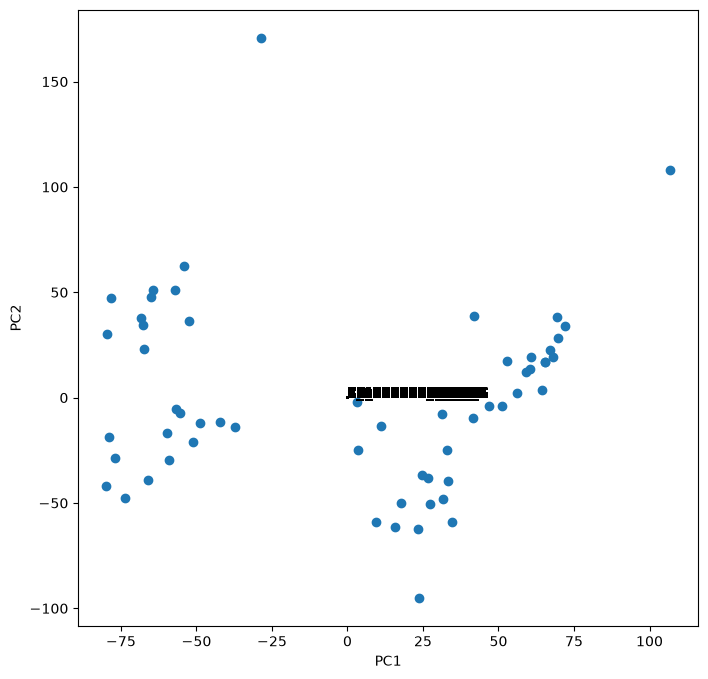

In [28]:
i, j = 0, 1
fig, ax = plt.subplots(1, 1, figsize=(8,8))
ax.scatter(scores[:, 0], scores[:, 1])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pca.components_.shape[1]):
    ax.arrow(0, 0, pca.components_[i,k], pca.components_[j,k])
    ax.text(pca.components_[i,k],
            pca.components_[j, k],
            df_T.columns[k])

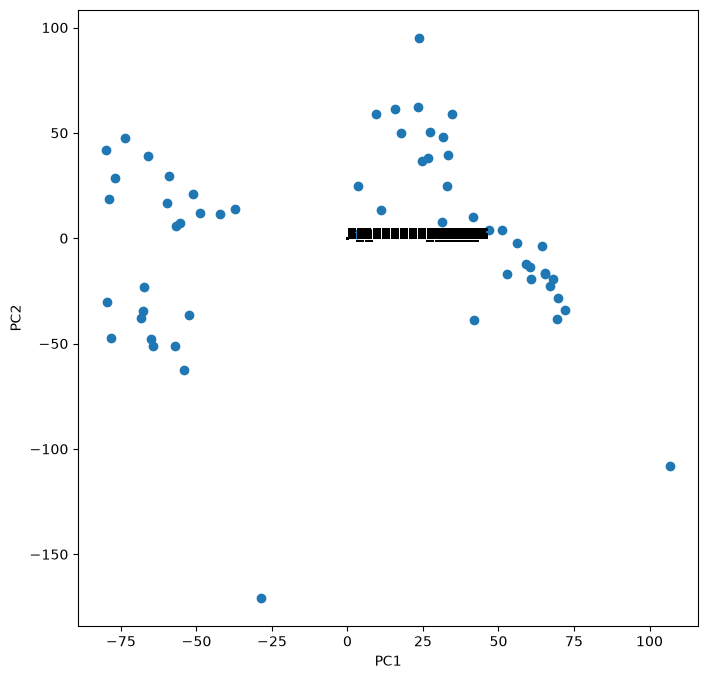

In [29]:
scale_arrow = s_ = 2
scores[:, 1] *= -1
pca.components_[1] *= -1
fig, ax = plt.subplots(1, 1, figsize=(8,8))
ax.scatter(scores[:, 0], scores[:, 1])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pca.components_.shape[1]):
    ax.arrow(0, 0, s_*pca.components_[i, k], s_*pca.components_[j,k])
    ax.text(s_*pca.components_[i,k],
            s_*pca.components_[j,k],
            df_T.columns[k])